# Quantium Task 2: Store Trial Assessment

**Goal:** a new chip layout was trialled in **stores 77, 86 and 88** from **February to April 2019**. Did it increase sales, and if so, why?

**Method:**
1. For each trial store, find a **control store** that behaved most like it *before* the trial, judged on both the shape of its monthly trend (correlation) and its size (magnitude distance).
2. Scale the control store to the trial store's size, then compare them month by month during the trial.
3. Test whether each trial month is outside the normal pre-trial gap between the two stores (t-test, 95% confidence).

Run `Task-1.ipynb` first. It creates `data/QVI_data.csv`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

DATA = Path("../data")
CHARTS = Path("../charts"); CHARTS.mkdir(exist_ok=True)
BLUE, GREY = "#2E86C1", "#7F8C99"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#E6E9ED", "axes.axisbelow": True})
pd.set_option("display.float_format", "{:,.3f}".format)

TRIAL_STORES = [77, 86, 88]
TRIAL_START, TRIAL_END = 201902, 201904

## 1. Monthly measures for every store

In [2]:
data = pd.read_csv(DATA / "QVI_data.csv", parse_dates=["DATE"])
data["YEARMONTH"] = data["DATE"].dt.year * 100 + data["DATE"].dt.month

monthly = (data.groupby(["STORE_NBR", "YEARMONTH"])
             .agg(total_sales=("TOT_SALES", "sum"),
                  n_customers=("LYLTY_CARD_NBR", "nunique"),
                  n_txns=("TXN_ID", "nunique"),
                  units=("PROD_QTY", "sum"))
             .reset_index())
monthly["txns_per_customer"] = monthly["n_txns"] / monthly["n_customers"]
monthly["chips_per_txn"] = monthly["units"] / monthly["n_txns"]
monthly["price_per_unit"] = monthly["total_sales"] / monthly["units"]
monthly.head()

,STORE_NBR,YEARMONTH,total_sales,n_customers,n_txns,units,txns_per_customer,chips_per_txn,price_per_unit
0,1,201807,188.900,47,49,58,1.043,1.184,3.257
1,1,201808,168.400,41,41,52,1.000,1.268,3.238
2,1,201809,268.100,57,59,71,1.035,1.203,3.776
3,1,201810,175.400,39,40,51,1.026,1.275,3.439
4,1,201811,184.800,44,45,55,1.023,1.222,3.360


Only stores with sales in **all 12 months** can be fair controls, otherwise the comparison has gaps. The **pre-trial period** is July 2018 to January 2019.

In [3]:
full_year = monthly.groupby("STORE_NBR")["YEARMONTH"].nunique().loc[lambda s: s == 12].index
monthly = monthly[monthly["STORE_NBR"].isin(full_year)]
pre = monthly[monthly["YEARMONTH"] < TRIAL_START]
print("Stores with a full year of data:", len(full_year), "of", data["STORE_NBR"].nunique())
print("Pre-trial months:", sorted(pre["YEARMONTH"].unique()))

Stores with a full year of data: 259 of 271
Pre-trial months: [np.int32(201807), np.int32(201808), np.int32(201809), np.int32(201810), np.int32(201811), np.int32(201812), np.int32(201901)]


## 2. Find the control stores

Each candidate store gets two scores per measure (total sales and number of customers), comparing it with the trial store over the pre-trial months:
- **Correlation:** do the two stores rise and fall together? (Pearson's r)
- **Magnitude distance:** are they a similar size? Scaled from 0 (least similar candidate) to 1 (most similar).

The final score averages both scores across both measures, and the highest-scoring store becomes the control.

In [4]:
def similarity(trial, measure):
    t = pre[pre["STORE_NBR"] == trial].set_index("YEARMONTH")[measure]
    rows = []
    for store, g in pre[pre["STORE_NBR"] != trial].groupby("STORE_NBR"):
        c = g.set_index("YEARMONTH")[measure].reindex(t.index)
        rows.append({"STORE_NBR": store, "corr": t.corr(c), "abs_diff": (t - c).abs().values})
    df = pd.DataFrame(rows)
    # magnitude distance: scale each month's absolute difference to 0-1 across candidates, then average
    diffs = np.vstack(df["abs_diff"].values)
    scaled = 1 - (diffs - diffs.min(axis=0)) / (diffs.max(axis=0) - diffs.min(axis=0))
    df["magnitude"] = scaled.mean(axis=1)
    return df.drop(columns="abs_diff").set_index("STORE_NBR")

def pick_control(trial):
    s = similarity(trial, "total_sales"); c = similarity(trial, "n_customers")
    score = (0.5 * s["corr"] + 0.5 * s["magnitude"]) * 0.5 + (0.5 * c["corr"] + 0.5 * c["magnitude"]) * 0.5
    out = pd.DataFrame({"sales_corr": s["corr"], "sales_magnitude": s["magnitude"],
                        "cust_corr": c["corr"], "cust_magnitude": c["magnitude"], "final_score": score})
    return out.sort_values("final_score", ascending=False)

CONTROL = {}
for trial in TRIAL_STORES:
    ranking = pick_control(trial)
    CONTROL[trial] = int(ranking.index[0])
    print(f"Trial store {trial} -> control store {CONTROL[trial]}")
    display(ranking.head(3))

Trial store 77 -> control store 233


,sales_corr,sales_magnitude,cust_corr,cust_magnitude,final_score
STORE_NBR,,,,,
233,0.974,0.987,0.966,0.991,0.979
50,0.898,0.976,0.709,0.932,0.879
35,0.691,0.909,0.893,0.900,0.848


Trial store 86 -> control store 155


,sales_corr,sales_magnitude,cust_corr,cust_magnitude,final_score
STORE_NBR,,,,,
155,0.870,0.963,0.829,0.972,0.909
114,0.751,0.938,0.855,0.956,0.875
138,0.796,0.947,0.622,0.932,0.824


Trial store 88 -> control store 237


,sales_corr,sales_magnitude,cust_corr,cust_magnitude,final_score
STORE_NBR,,,,,
237,0.110,0.949,0.959,0.982,0.750
123,0.402,0.857,0.660,0.887,0.702
7,0.699,0.788,0.346,0.838,0.668


Each trial store now has its **own** control store: **77 → 233, 86 → 155, 88 → 237**.

One caveat: store 237's **sales** correlation with store 88 is low (0.11). It was chosen because its customer numbers track store 88 very closely (r = 0.96) and its sales are a similar size. So store 88's results are less certain than the other two.

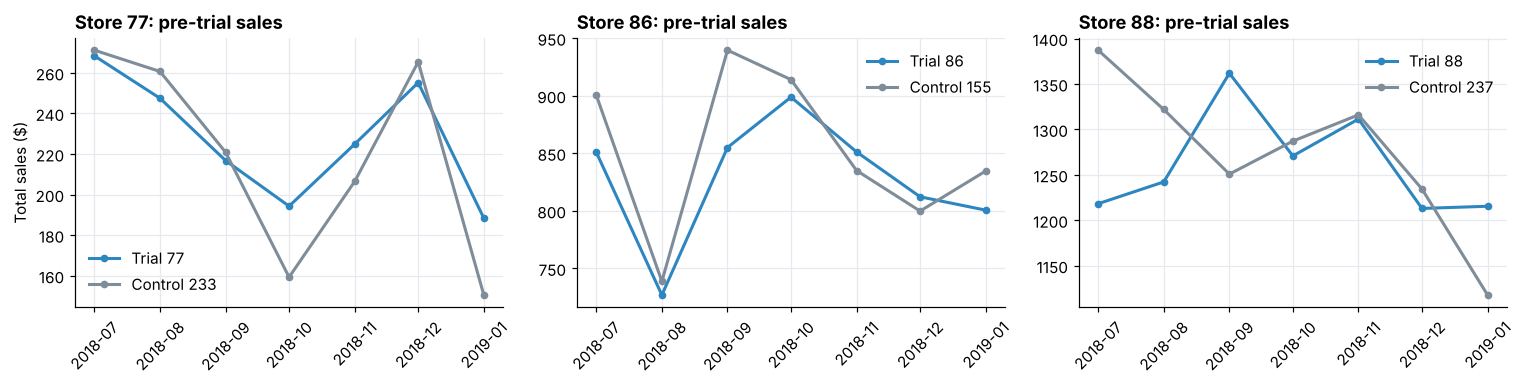

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=False)
for ax, trial in zip(axes, TRIAL_STORES):
    for store, colour, label in [(trial, BLUE, f"Trial {trial}"), (CONTROL[trial], GREY, f"Control {CONTROL[trial]}")]:
        s = pre[pre["STORE_NBR"] == store]
        ax.plot(pd.to_datetime(s["YEARMONTH"].astype(str), format="%Y%m"), s["total_sales"], color=colour, lw=2, marker="o", ms=4, label=label)
    ax.set_title(f"Store {trial}: pre-trial sales", loc="left", fontweight="bold"); ax.legend(frameon=False)
    ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Total sales ($)")
plt.tight_layout(); plt.show()

## 3. Did the trial work?

For each trial store:
1. **Scale** the control store so its pre-trial total matches the trial store's.
2. Work out the **% difference** between trial and scaled control each month.
3. The pre-trial % differences show the normal month-to-month gap. A trial month counts as a **significant increase** if its t-value is above the one-sided 95% critical value (t > 1.94: 7 pre-trial months gives 6 degrees of freedom). The difference is kept signed, so a month where the trial store did *worse* can never count as an uplift.

In [6]:
def assess(trial, measure):
    control = CONTROL[trial]
    t = monthly[monthly["STORE_NBR"] == trial].set_index("YEARMONTH")[measure]
    c = monthly[monthly["STORE_NBR"] == control].set_index("YEARMONTH")[measure]
    pre_months = t.index < TRIAL_START
    scaled_c = c * t[pre_months].sum() / c[pre_months].sum()
    pct_diff = (t - scaled_c) / scaled_c   # signed: positive = trial store did better
    sd = pct_diff[pre_months].std()
    dof = pre_months.sum() - 1
    res = pd.DataFrame({"trial": t, "scaled_control": scaled_c, "pct_diff": pct_diff,
                        "t_value": pct_diff / sd})
    res["significant"] = (res["t_value"] > stats.t.ppf(0.95, dof)) & ~pre_months
    res.attrs.update(sd=sd, dof=dof, control=control, measure=measure)
    return res

print("One-sided 95% critical t-value (6 degrees of freedom):", round(stats.t.ppf(0.95, 6), 3))

One-sided 95% critical t-value (6 degrees of freedom): 1.943


In [7]:
def plot_assessment(trial):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for ax, measure, label in [(axes[0], "total_sales", "Total sales ($)"), (axes[1], "n_customers", "Customers")]:
        r = assess(trial, measure)
        x = pd.to_datetime(r.index.astype(str), format="%Y%m")
        sd = r.attrs["sd"]
        ax.fill_between(x, r["scaled_control"] * (1 - 2 * sd), r["scaled_control"] * (1 + 2 * sd),
                        color=GREY, alpha=0.18, lw=0, label="Control 95% range")
        ax.plot(x, r["scaled_control"], color=GREY, lw=2, label=f"Control {CONTROL[trial]} (scaled)")
        ax.plot(x, r["trial"], color=BLUE, lw=2, marker="o", ms=4, label=f"Trial {trial}")
        ax.axvspan(pd.Timestamp("2019-02-01"), pd.Timestamp("2019-04-30"), color=BLUE, alpha=0.06)
        ax.set_title(f"Store {trial}: {label.split(' (')[0].lower()}", loc="left", fontweight="bold")
        ax.set_ylabel(label); ax.legend(frameon=False, fontsize=8)
    plt.tight_layout(); fig.savefig(CHARTS / f"t2_store_{trial}.png", bbox_inches="tight"); plt.show()

def trial_table(trial):
    out = []
    for measure in ["total_sales", "n_customers"]:
        r = assess(trial, measure).loc[TRIAL_START:TRIAL_END]
        out.append(r[["trial", "scaled_control", "t_value", "significant"]].assign(measure=measure))
    return pd.concat(out).reset_index().set_index(["measure", "YEARMONTH"])

### Store 77

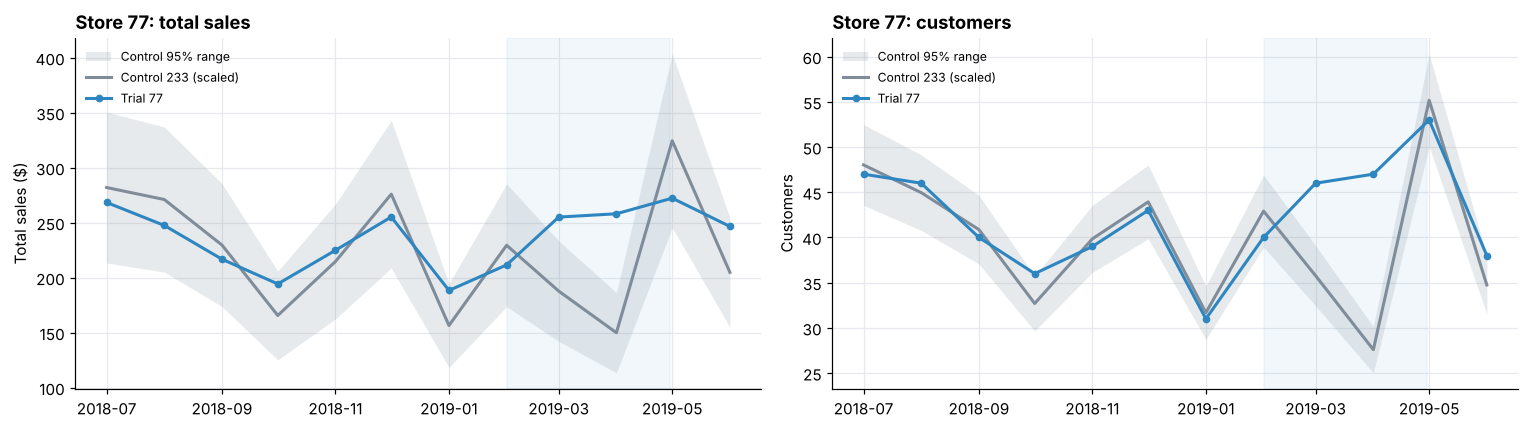

trial  scaled_control  t_value  significant
measure     YEARMONTH                                              
total_sales 201902    211.600         229.473   -0.640        False
            201903    255.100         187.779    2.945         True
            201904    258.100         149.932    5.926         True
n_customers 201902     40.000          42.913   -1.460        False
            201903     46.000          35.761    6.158         True
            201904     47.000          27.587   15.135         True

In [8]:
plot_assessment(77)
trial_table(77)

**Store 77:** sales were significantly higher than the control in **March and April** (+28% over the trial), and so were customer numbers. The uplift came mainly from **more customers**, while purchases per customer barely changed.

### Store 86

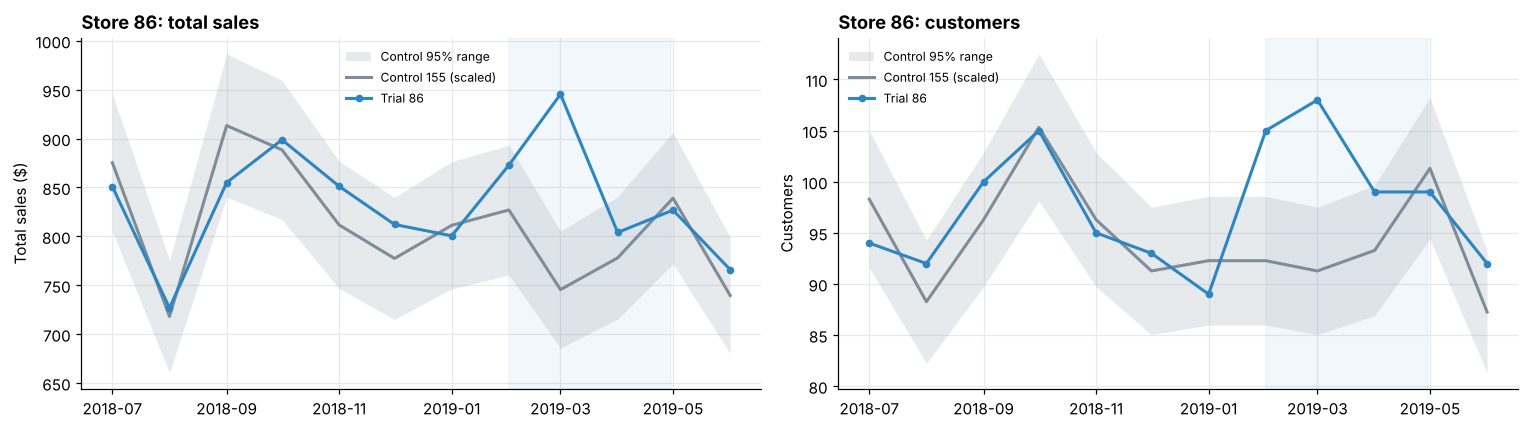

trial  scaled_control  t_value  significant
measure     YEARMONTH                                              
total_sales 201902    872.800         827.020    1.379        False
            201903    945.400         745.562    6.678         True
            201904    804.000         778.028    0.832        False
n_customers 201902    105.000          92.276    4.040         True
            201903    108.000          91.273    5.369         True
            201904     99.000          93.279    1.797        False

In [9]:
plot_assessment(86)
trial_table(86)

**Store 86:** customer numbers were significantly higher in **February and March**, but sales only rose significantly in **March**. More people bought chips without total sales rising as much, which could mean a price promotion. **Worth checking with Julia** whether pricing changed in this store during the trial.

### Store 88

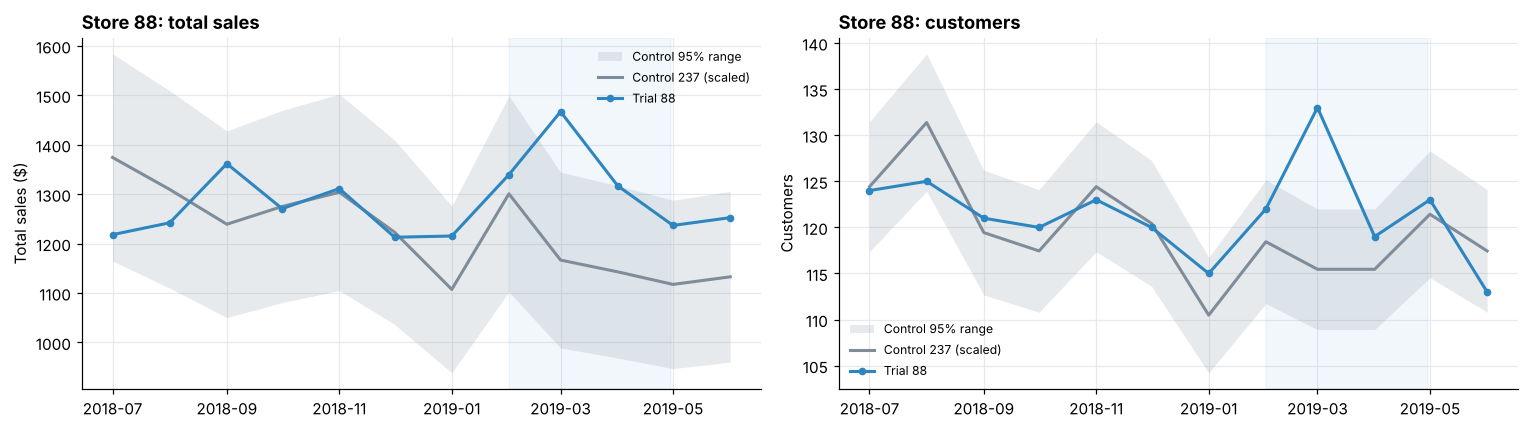

trial  scaled_control  t_value  significant
measure     YEARMONTH                                                
total_sales 201902    1,339.600       1,300.879    0.390        False
            201903    1,467.000       1,166.729    3.375         True
            201904    1,317.000       1,142.951    1.997         True
n_customers 201902      122.000         118.441    1.060        False
            201903      133.000         115.455    5.362         True
            201904      119.000         115.455    1.083        False

In [10]:
plot_assessment(88)
trial_table(88)

**Store 88:** sales were significantly higher in **March and April**, but customer numbers only rose in March. Here the uplift came more from **existing customers buying more often** (transactions per customer rose from 1.20 to 1.25 while the control's fell).

In [11]:
summary = []
for trial in TRIAL_STORES:
    for measure in ["total_sales", "n_customers"]:
        r = assess(trial, measure).loc[TRIAL_START:TRIAL_END]
        summary.append({"trial_store": trial, "control_store": CONTROL[trial], "measure": measure,
                        "uplift_%": (r["trial"].sum() / r["scaled_control"].sum() - 1) * 100,
                        "significant_months": f"{int(r['significant'].sum())} of 3"})
summary = pd.DataFrame(summary)
summary.round(1)

,trial_store,control_store,measure,uplift_%,significant_months
0,77,233,total_sales,27.800,2 of 3
1,77,233,n_customers,25.200,2 of 3
2,86,155,total_sales,11.600,1 of 3
3,86,155,n_customers,12.700,2 of 3
4,88,237,total_sales,14.200,2 of 3
5,88,237,n_customers,7.100,1 of 3


In [12]:
ppc = []
for trial in TRIAL_STORES:
    for store, role in [(trial, "trial"), (CONTROL[trial], "control")]:
        m = monthly[monthly["STORE_NBR"] == store]
        for period, rows in [("pre-trial", m[m["YEARMONTH"] < TRIAL_START]),
                             ("trial", m[m["YEARMONTH"].between(TRIAL_START, TRIAL_END)])]:
            ppc.append({"trial_store": trial, "role": role, "period": period,
                        "txns_per_customer": rows["n_txns"].sum() / rows["n_customers"].sum()})
pd.DataFrame(ppc).pivot_table(index=["trial_store", "role"], columns="period", values="txns_per_customer")[["pre-trial", "trial"]].round(3)

period               pre-trial  trial
trial_store role                     
77          control      1.033  1.029
            trial        1.053  1.038
86          control      1.263  1.232
            trial        1.238  1.205
88          control      1.200  1.165
            trial        1.200  1.251

## 4. Conclusion

| Trial store | Control | Sales uplift | Significant sales months | Customer uplift | Significant customer months |
|---|---|---|---|---|---|
| 77 | 233 | +27.8% | Mar, Apr | +25.2% | Mar, Apr |
| 86 | 155 | +11.6% | Mar | +12.7% | Feb, Mar |
| 88 | 237 | +14.2% | Mar, Apr | +7.1% | Mar |

**The trial worked:** all three stores sold more than their control stores, with statistically significant uplifts in at least one trial month. Stores 77 and 86 grew mainly by **attracting more customers**, while store 88 grew by **customers buying more often**.

**Recommendation:** roll the new layout out to similar stores. Before doing so, check how store 86 implemented the trial, since its customers rose more than its sales did, and treat store 88's result with some caution because its control store is a weaker match on sales.